# CIS I — Assignment 3: Surface Registration with a Tracked Pointer

This notebook walks through the registration scenario of the handout
(Figure 1): a femur CT mesh, a reference body attached to the femur, a
tracked pointer, and an optical tracker. You **design** the pointer and
reference body and the camera placement, **collect** tip positions on
instructor-selected quasi-planar patches under a simulated clock, and
**register** the reference body to the CT mesh (`F_reg`, reference body → CT)
with a TRE of at most 2 mm, in reasonable simulated time and under 10 minutes
of wall-clock time.

The simulation (the femur's pose in the workspace, the true registration, the
pointer placement, the tracker and the simulated clock) runs on the **course
server**. Your code talks to it through a `Session` object
(`src/session.py`): `initial_registration_guess()`, `place_pointer(patch)`,
`sample_marker_bodies()`, `elapsed()`. The server only ever returns what the
tracker would report; nothing about the hidden truth leaves it. Grading runs
the same `Session` interface in-process on the instructor's machine with
different seeds.

Your code lives in `src/student/` (stubs raising `NotImplementedError`),
driven from here and unit-tested from `tests/`. The conventions are in the
README; read them first.

In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

import numpy as np
from src import vct3, Rot, Frame, load_sur, load_patch_boxes, RemoteSession, SceneDesign
from src.student import closest_point, icp, uncertainty, report, workflow

np.set_printoptions(precision=4, suppress=True)

DATA = os.path.join("..", "data")
mesh = load_sur(os.path.join(DATA, "ProximalFemurMeshFile.sur"))
boxes = load_patch_boxes(os.path.join(DATA, "box-centroids-rotations-world.json"))
print(f"mesh: {mesh.n_vertices} vertices, {mesh.n_triangles} triangles; {len(boxes)} patch boxes")

mesh: 1568 vertices, 3135 triangles; 46 patch boxes


## Step 1: Design the scene

Specify the tracker pose, the marker layouts of the reference body and the
pointer (both manufactured exactly), and the pointer tip `p_tip`. Keep in mind:

- The tracker's usable volume is a frustum along its **local +z axis**:
  100–220 cm in front of the camera, widening from a 100 cm to a 200 cm square.
  The femur sits near the workspace origin (±50 mm, ±0.3 rad).
- The pointer's +z axis points away from the bone when it touches the surface,
  so its markers should be on the +z side of the tip (e.g. `p_tip = (0, 0, -150)`
  with markers around the origin). Marker spread sets how noisy each pose is;
  the lever arms `‖p_tip‖` and the tip-to-reference distance multiply that noise.
- The reference body is attached close to the femur surface;
  `session.nominal_reference_pose()` gives its approximate workspace pose.

Put the same values in `workflow.design_scene()` — grading calls that function.

In [2]:
F_tracker_approx = Frame(Rot('x', np.pi), vct3(0, 0, 1900))     # Frame, camera pose relative to the workspace (looks along its local +z)
ref_marker_positions = [    # >= 3 points, reference-body coordinates
    vct3(-45, -25, 0),
    vct3(50, -30, 0),
    vct3(0, 20, 0)
]
ptr_marker_positions = [    # >= 3 points, pointer coordinates
    vct3(-50,  -20, 0),
    vct3( 50,  -20, 0),
    vct3(  0,   30, 0)
]
p_tip = vct3(0, 0, -150)                # vct3, tip in pointer coordinates

design = SceneDesign(F_tracker_approx, ref_marker_positions, ptr_marker_positions, p_tip)

## Step 2: Open a session on the course server

`SERVER_URL` and (if announced) `COURSE_TOKEN` are given on Piazza. A session
owns one hidden scene and its own simulated clock. Passing a `seed` makes a
practice session reproducible (same hidden truth and sample sequence);
grading uses other seeds and the same parameters. If the server is unreachable
you get a `RuntimeError` with the reason — check the URL and your network.

Everything below runs against `session`; the session keeps running until you
`session.close()` it or it idles for a few hours.

In [3]:
SERVER_URL = "https://painting-classical-dosage-similar.trycloudflare.com"
COURSE_TOKEN = "cis1-a3-yupRn9rDiBUA"
SEED = 1

session = RemoteSession(SERVER_URL, design, seed=SEED, token=COURSE_TOKEN)
F0_reg = session.initial_registration_guess()
print(f"session {session.session_id} ({session.mode}), {session.n_patches} patches, clock {session.elapsed():.2f} s")
print("F0_reg translation:", F0_reg.p.vec.ravel())

session 3eb92da17a5e79a4 (practice), 46 patches, clock 0.00 s
F0_reg translation: [25.     83.3095  0.    ]


### Step 2.1: Visibility check

Before spending simulated time, check (locally, for free) that the reference
body and the pointer at every patch stay inside the frustum, using the nominal
poses the server returned.

In [4]:
ref_pts = [session.nominal_reference_pose() * a for a in ref_marker_positions]
print("reference body visible:", session.is_visible(ref_pts))
invisible = [i for i in range(session.n_patches)
             if not session.is_visible([session.nominal_pointer_pose(i) * a for a in ptr_marker_positions])]
print(f"pointer invisible on {len(invisible)}/{session.n_patches} patches: {invisible}")

reference body visible: True
pointer invisible on 0/46 patches: []


## Step 3: Unit tests

`tests/test_student.py` exercises your code offline (it needs no server):
complete tests fail with `NotImplementedError` until you implement what they
call; the `TODO` ones are yours to write.

In [5]:
os.environ["COURSE_TOKEN"] = COURSE_TOKEN
os.environ["SERVER_URL"] = SERVER_URL
# print(repr(os.environ.get("COURSE_TOKEN")))
!{sys.executable} -m pytest ../tests -q -p no:cacheprovider

.........                                                                [100%]
9 passed in 50.33s


## Step 4: Closest point on the mesh

Implement `closest_point.closest_point_on_triangle` and the vectorised
`closest_point.closest_points_on_mesh`. Time it: ICP calls it every iteration
on all your samples.

In [6]:
rng = np.random.default_rng(0)
q = rng.uniform(-60, 60, size=(200, 3))
t0 = time.perf_counter()
closest, tri, dist = closest_point.closest_points_on_mesh(q, mesh)
print(f"200 queries in {time.perf_counter() - t0:.3f} s; mean distance {dist.mean():.2f} mm")

200 queries in 0.862 s; mean distance 23.38 mm


## Step 5: Collect samples

Design `workflow.plan_patches` (which patches, how many samples each — the
residual statistics and the simulated time both depend on it) and
`workflow.collect_samples`: `session.place_pointer(patch)` (1 s simulated),
`session.sample_marker_bodies()` (0.03 s), then
`d_k = F_ref^-1 · F_ptr · p_tip` in reference-body coordinates. A body outside
the frustum comes back as `None` and still costs the time. Each call is one
HTTP round trip, so a few hundred samples take a few seconds of real time.

In [7]:
plan = workflow.plan_patches(boxes, n_patches=46, samples_per_patch=4)   # TODO: your design
samples = workflow.collect_samples(session, plan)
print(f"{len(samples)} samples from {len(set(samples.patch_ids))} patches in {samples.t_collect:.1f} s simulated")

184 samples from 46 patches in 189.5 s simulated


## Step 6: Coarse registration and ICP

`F0_reg` is only a rough guess, so start with `icp.coarse_registration` (patch
sample centroids ↔ box centres, and the box planes), then `icp.icp` with your
outlier rejection. Explain both choices in the report.

In [8]:
d = samples.as_array()
by_patch = {}
for pid, dk in zip(samples.patch_ids, d):
    by_patch.setdefault(pid, []).append(dk)
F_coarse = icp.coarse_registration({k: np.array(v) for k, v in by_patch.items()}, boxes)
result = icp.icp(d, mesh, F_coarse)
print(f"ICP: {result.n_iter} iterations, converged={result.converged}, "
      f"{result.inlier_mask.sum()}/{len(d)} samples used")
print("residual rms per iteration:", np.round(result.history, 3))

ICP: 24 iterations, converged=True, 158/184 samples used
residual rms per iteration: [0.924 0.651 0.478 0.38  0.324 0.275 0.249 0.238 0.238 0.234 0.231 0.229
 0.234 0.233 0.233 0.232 0.232 0.232 0.225 0.224 0.224 0.224 0.224 0.224]


## Step 7: Uncertainty and the required report

Estimate `η_reg ~ N(μ, C_reg)` from the final fit and predict the TRE over
the mesh vertices (`uncertainty.py`), then assemble a `RegistrationReport`
(`workflow.run_registration` must do all of this headlessly).

In [9]:
mu, C_reg = uncertainty.registration_covariance(result, F0_reg)
pred = uncertainty.predicted_tre(mesh, result.F_reg, C_reg)
print("mu:", mu)
print("predicted TRE rms (mm):", pred["rms"])

mu: [ 0.3673  0.3659 -0.1933  1.4365 -2.4749 -5.3654]
predicted TRE rms (mm): 0.09612191742329732


## Step 8: Validation against the server's ground truth (practice sessions only)

The server never reveals `F*_reg`, but a practice session will score an
estimate for you: `session.evaluate_tre(F_reg)` returns TRE statistics over the
mesh vertices and `session.true_outliers()` the indices of the samples that
were outliers. Use them only here, for validation and your report: compare
achieved TRE vs predicted TRE vs residual statistics (FRE), and flagged vs
true outliers. Repeat for at least one other `SEED` and put the tables in
your report. Graded sessions refuse these calls.

In [10]:
import numpy as np


def validate_registration(session, seed, F_reg, pred, residuals,
                          observed_ids, flagged_ids):
    tre = session.evaluate_tre(F_reg)
    true_ids = set(session.true_outliers()) & set(observed_ids)
    flagged_ids = set(flagged_ids)
    residuals = np.asarray(residuals, dtype=float)

    fre = (
        np.sqrt(np.mean(residuals**2)),
        np.mean(residuals),
        np.max(residuals),
        np.percentile(residuals, 90),
    )

    print(f"Seed {seed} | {tre.n} mesh vertices | "
          f"{session.elapsed():.1f} s simulated")
    print(f"{'Metric (mm)':<23} {'RMS':>9} {'Mean':>9} {'Max':>9} {'P90':>9}")
    for label, values in (
        ("Achieved TRE", (tre.rms, tre.mean, tre.max, tre.p90)),
        ("Predicted TRE", tuple(pred[key] for key in ("rms", "mean", "max", "p90"))),
        ("Inlier residuals (FRE)", fre),
    ):
        print(f"{label:<23}" + "".join(f"{value:>10.4f}" for value in values))

    print(f"Inlier residual std: {np.std(residuals):.4f} mm")
    print(f"Outliers correctly flagged: {len(flagged_ids & true_ids)}")
    print(f"False alarms: {len(flagged_ids - true_ids)}")
    print(f"Missed observed outliers: {len(true_ids - flagged_ids)}")


observed_ids = [handle.sample_index for handle in samples.handles]
flagged_ids = [
    sample_id
    for sample_id, is_inlier in zip(observed_ids, result.inlier_mask)
    if not is_inlier
]

validate_registration(
    session, SEED, result.F_reg, pred,
    result.residuals[result.inlier_mask],
    observed_ids, flagged_ids,
)

Seed 1 | 1568 mesh vertices | 189.5 s simulated
Metric (mm)                   RMS      Mean       Max       P90
Achieved TRE               0.0713    0.0649    0.1280    0.1092
Predicted TRE              0.0961    0.0941    0.1405    0.1256
Inlier residuals (FRE)     0.2236    0.1738    0.6943    0.3638
Inlier residual std: 0.1406 mm
Outliers correctly flagged: 25
False alarms: 1
Missed observed outliers: 0


In [11]:
from pathlib import Path

workflow_path = Path(workflow.__file__).resolve()
source = workflow_path.read_text(encoding="utf-8")
print("Loading:", workflow_path)

if "TODO: implement run_registration" in source:
    raise RuntimeError(
        "The saved workflow.py still has the old stub. "
        "Replace it with the Step 7 version, then rerun this cell."
    )

exec(compile(source, str(workflow_path), "exec"), vars(workflow))

Loading: C:\Users\akhil\dev\CIS_I_Course\assignments\assignment3\src\student\workflow.py


In [12]:
second_seed = SEED + 1
second_session = RemoteSession(
    SERVER_URL, workflow.design_scene(), seed=second_seed, token=COURSE_TOKEN
)

try:
    final = workflow.run_registration(second_session, mesh, boxes)
    observed = [row for row in final.samples if row["d_ref"] is not None]

    validate_registration(
        second_session, second_seed, final.F_reg, final.predicted_tre,
        [row["residual_mm"] for row in observed if row["used"]],
        [row["sample_index"] for row in observed],
        [row["sample_index"] for row in observed if row["reason"] == "icp_outlier"],
    )

    final.to_json(f"registration_report_seed_{second_seed}.json")
finally:
    second_session.close()

Seed 2 | 1568 mesh vertices | 189.5 s simulated
Metric (mm)                   RMS      Mean       Max       P90
Achieved TRE               0.1040    0.0950    0.1820    0.1513
Predicted TRE              0.0791    0.0776    0.1092    0.1003
Inlier residuals (FRE)     0.1830    0.1423    0.4701    0.3235
Inlier residual std: 0.1150 mm
Outliers correctly flagged: 16
False alarms: 4
Missed observed outliers: 1


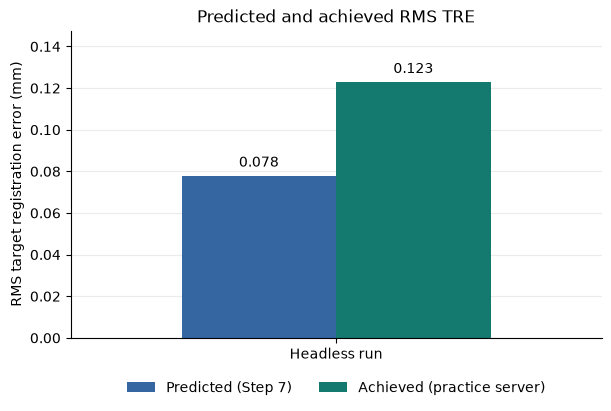

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Each row is (run label, predicted RMS TRE, achieved RMS TRE).
tre_runs = [
    ("Headless run", 0.078, 0.123),
    # Add the other run here once you have both values.
]

labels, predicted, achieved = zip(*tre_runs)
x = np.arange(len(labels))
bar_width = 0.32

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")

predicted_bars = ax.bar(
    x - bar_width / 2, predicted, bar_width,
    label="Predicted (Step 7)", color="#3566a1",
)
achieved_bars = ax.bar(
    x + bar_width / 2, achieved, bar_width,
    label="Achieved (practice server)", color="#14796e",
)

for bars in (predicted_bars, achieved_bars):
    ax.bar_label(bars, fmt="%.3f", padding=4)

ax.set_xticks(x, labels)
ax.set_xlim(-0.55, len(labels) - 0.45)
ax.set_ylim(0, 1.2 * max(*predicted, *achieved))
ax.set_ylabel("RMS target registration error (mm)")
ax.set_title("Predicted and achieved RMS TRE")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=2, frameon=False)

fig.savefig("Step_8_RMS_TRE.png", dpi=300, bbox_inches="tight")
plt.show()


## Achieved performance

Run the full headless pipeline once more on a fresh session (this is exactly
what grading calls) and print the report. Put the same tables in your written
report, for more than one seed.

In [14]:
session.close()
session = RemoteSession(SERVER_URL, workflow.design_scene(), seed=SEED, token=COURSE_TOKEN)

final = workflow.run_registration(session, mesh, boxes)
print(final.to_text())
final.to_json("registration_report.json")
print("\nTRE rms (server, practice only):", round(session.evaluate_tre(final.F_reg).rms, 3), "mm")
session.close()

F_reg (reference body -> CT):
     0.91724    0.24599    0.31332   44.91598
    -0.11521    0.91676   -0.38247   70.98637
    -0.38132    0.31472    0.86922   11.30202
     0.00000    0.00000    0.00000    1.00000

Patches (46):  id  samples  used  rejected
    0      4      2      2
    1      4      4      0
    2      4      2      2
    3      4      3      1
    4      4      2      2
    5      4      2      2
    6      4      3      1
    7      4      4      0
    8      4      4      0
    9      4      4      0
   10      4      3      1
   11      4      3      1
   12      4      4      0
   13      4      3      1
   14      4      3      1
   15      4      3      1
   16      4      3      1
   17      4      4      0
   18      4      3      1
   19      4      4      0
   20      4      3      1
   21      4      4      0
   22      4      3      1
   23      4      3      1
   24      4      3      1
   25      4      4      0
   26      4      4      0
   27      4 